# Notebook 1 — EDA
Filename: P3_MovieGenre-1_EDA_<TeamName>.ipynb
Explore the movies, genre labels, and plot text in mpst_imdb_movies.csv before you
model anything.
Not model inputs: startYear, runtimeMinutes, averageRating, and numVotes are for
analysis and filtering only.
Your submission MUST include:
1 Movie characteristics
• Distributions of startYear, runtimeMinutes, averageRating, and numVotes (log scale)
• Box plot of averageRating by genre
• Vote filter: choose and justify a minimum numVotes, and report how many rows it drops
per split. Notebooks 2 and 3 apply it. Don't overdo it
2 Genre / class balance
• Plot positive counts and rates for ALL genres
• Correlation heatmap of the genre dummies
3 Text characteristics and vocabulary
• Synopsis length (characters and approximate tokens): mean, median, min, max
• Top terms within a few genres vs. overall — any vocabulary that separates the classes?

## IMPORT PACKAGE 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
 
CSV_PATH = Path("mpst_imdb_movies.csv")              # same folder as the notebooks
MIN_VOTES = 100                      

## LOAD DATA 

In [2]:
df = pd.read_csv(CSV_PATH)
print("shape:", df.shape)
df.head(5)

shape: (11824, 33)


,imdb_id,primaryTitle,plot_synopsis,synopsis_source,split,startYear,runtimeMinutes,averageRating,numVotes,Action,Adult,Adventure,Animation,Biography,Comedy,Crime,Documentary,Drama,Family,Fantasy,Film-Noir,History,Horror,Music,Musical,Mystery,News,Romance,Sci-Fi,Sport,Thriller,War,Western
0,tt0057603,Black Sabbath,Note: this synopsis is for the orginal Italian...,imdb,train,1963.0,92.0,7.0,12895,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,tt0033045,The Shop Around the Corner,"Matuschek's, a gift store in Budapest, is the ...",imdb,test,1940.0,99.0,8.0,35221,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,tt0113862,Mr. Holland's Opus,"Glenn Holland, not a morning person by anyone'...",imdb,train,1995.0,143.0,7.3,40547,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,tt0086250,Scarface,"In May 1980, a Cuban man named Tony Montana (A...",imdb,val,1983.0,170.0,8.3,858294,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,tt1315981,A Single Man,George Falconer (Colin Firth) approaches a car...,imdb,val,2009.0,99.0,7.5,114520,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


# LABELING THE COLUMNS 

In [3]:
known_cols = {"imdb_id", "primaryTitle", "plot_synopsis", "startYear",
              "runtimeMinutes", "averageRating", "numVotes", "split", "genres"}
genre_cols = [
    c for c in df.columns
    if c not in known_cols
    and pd.api.types.is_numeric_dtype(df[c])
    and df[c].dropna().isin([0, 1]).all()
]
print(len(genre_cols), "genre columns found:")
print(genre_cols)

24 genre columns found:
['Action', 'Adult', 'Adventure', 'Animation', 'Biography', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'Film-Noir', 'History', 'Horror', 'Music', 'Musical', 'Mystery', 'News', 'Romance', 'Sci-Fi', 'Sport', 'Thriller', 'War', 'Western']


# HISTOGRAMS 

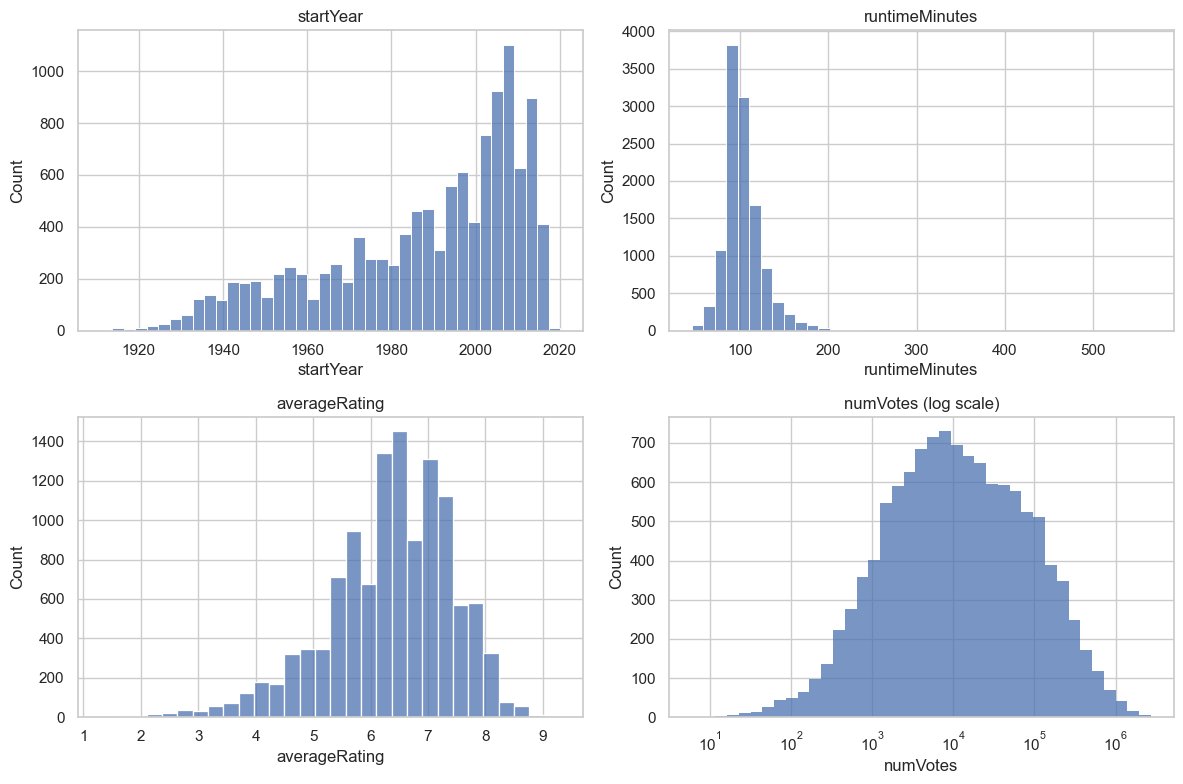

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["startYear"].dropna(), bins=40, ax=axes[0, 0])
axes[0, 0].set_title("startYear")

sns.histplot(df["runtimeMinutes"].dropna(), bins=40, ax=axes[0, 1])
axes[0, 1].set_title("runtimeMinutes")

sns.histplot(df["averageRating"].dropna(), bins=30, ax=axes[1, 0])
axes[1, 0].set_title("averageRating")

votes = df["numVotes"].dropna()
votes = votes[votes > 0]
sns.histplot(votes, bins=np.logspace(np.log10(votes.min()), np.log10(votes.max()), 40),
             ax=axes[1, 1])
axes[1, 1].set_xscale("log")
axes[1, 1].set_title("numVotes (log scale)")

plt.tight_layout()
plt.show()

# BOXPLOT

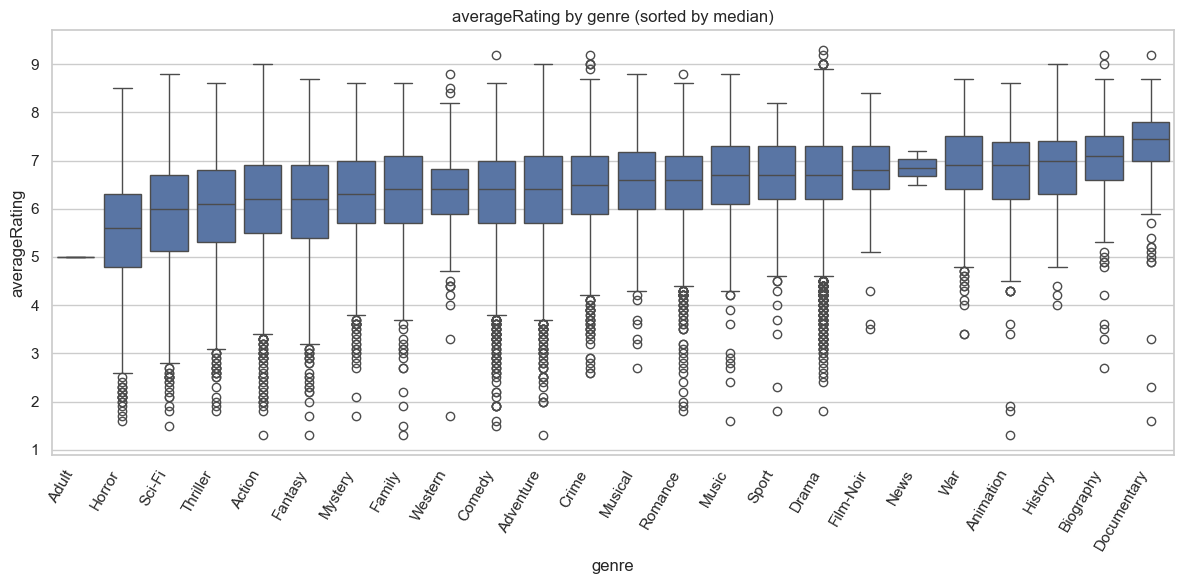

In [5]:
rows = []
for g in genre_cols:
    ratings = df.loc[df[g] == 1, "averageRating"].dropna()
    rows.append(pd.DataFrame({"genre": g, "averageRating": ratings}))
rating_by_genre = pd.concat(rows, ignore_index=True)

order = (rating_by_genre.groupby("genre")["averageRating"].median()
         .sort_values().index)

plt.figure(figsize=(12, 6))
sns.boxplot(data=rating_by_genre, x="genre", y="averageRating", order=order)
plt.xticks(rotation=60, ha="right")
plt.title("averageRating by genre (sorted by median)")
plt.tight_layout()
plt.show()

# VOTE FILTER 

In [6]:
print("splits found:", df["split"].value_counts().to_dict())
 
cutoffs = [0, 10, 50, 100, 500, 1000, 5000]
summary = []
for c in cutoffs:
    kept = df[df["numVotes"] >= c]
    row = {"min_votes": c, "rows_kept": len(kept),
           "pct_kept": round(100 * len(kept) / len(df), 1)}
    summary.append(row)
pd.DataFrame(summary)

splits found: {'train': 7596, 'test': 2360, 'val': 1868}


,min_votes,rows_kept,pct_kept
0,0,11824,100.0
1,10,11821,100.0
2,50,11782,99.6
3,100,11695,98.9
4,500,11089,93.8
5,1000,10385,87.8
6,5000,7570,64.0


# DROP OFF PER SPLIT

In [7]:
before = df.groupby("split").size().rename("before")
df_f = df[df["numVotes"] >= MIN_VOTES].copy()
after = df_f.groupby("split").size().rename("after")
 
drop_table = pd.concat([before, after], axis=1).fillna(0).astype(int)
drop_table["dropped"] = drop_table["before"] - drop_table["after"]
drop_table["pct_dropped"] = (100 * drop_table["dropped"] / drop_table["before"]).round(1)
drop_table.loc["TOTAL"] = [before.sum(), after.sum(),
                           before.sum() - after.sum(),
                           round(100 * (before.sum() - after.sum()) / before.sum(), 1)]
print(f"Vote filter: numVotes >= {MIN_VOTES}")
drop_table

Vote filter: numVotes >= 100


,before,after,dropped,pct_dropped
split,,,,
test,2360.0,2330.0,30.0,1.3
train,7596.0,7517.0,79.0,1.0
val,1868.0,1848.0,20.0,1.1
TOTAL,11824.0,11695.0,129.0,1.1


# BAR CHART 

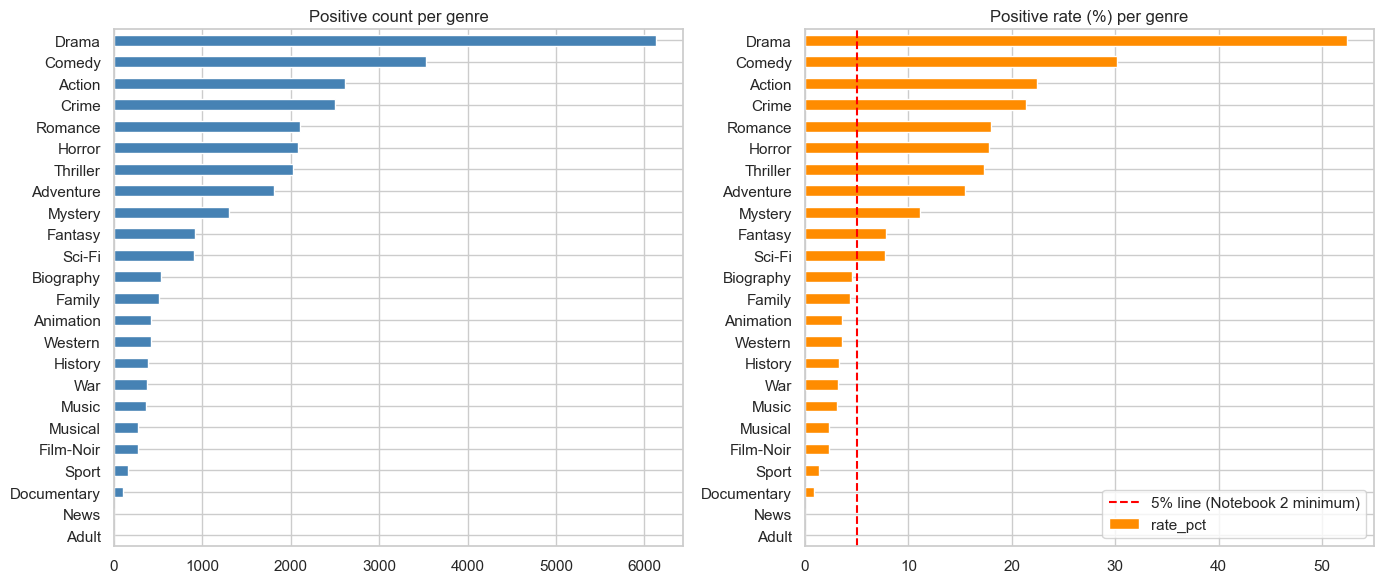

,positives,rate_pct
Drama,6131,52.42
Comedy,3533,30.21
Action,2618,22.39
Crime,2501,21.39
Romance,2103,17.98
Horror,2079,17.78
Thriller,2027,17.33
Adventure,1805,15.43
Mystery,1302,11.13
Fantasy,911,7.79


In [8]:
balance = pd.DataFrame({
    "positives": df_f[genre_cols].sum(),
    "rate_pct": (100 * df_f[genre_cols].mean()).round(2),
}).sort_values("positives", ascending=False)
 
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
balance["positives"].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Positive count per genre")
axes[0].invert_yaxis()
 
balance["rate_pct"].plot.barh(ax=axes[1], color="darkorange")
axes[1].axvline(5, color="red", linestyle="--", label="5% line (Notebook 2 minimum)")
axes[1].set_title("Positive rate (%) per genre")
axes[1].invert_yaxis()
axes[1].legend()
 
plt.tight_layout()
plt.show()
balance


# HEAT MAP 

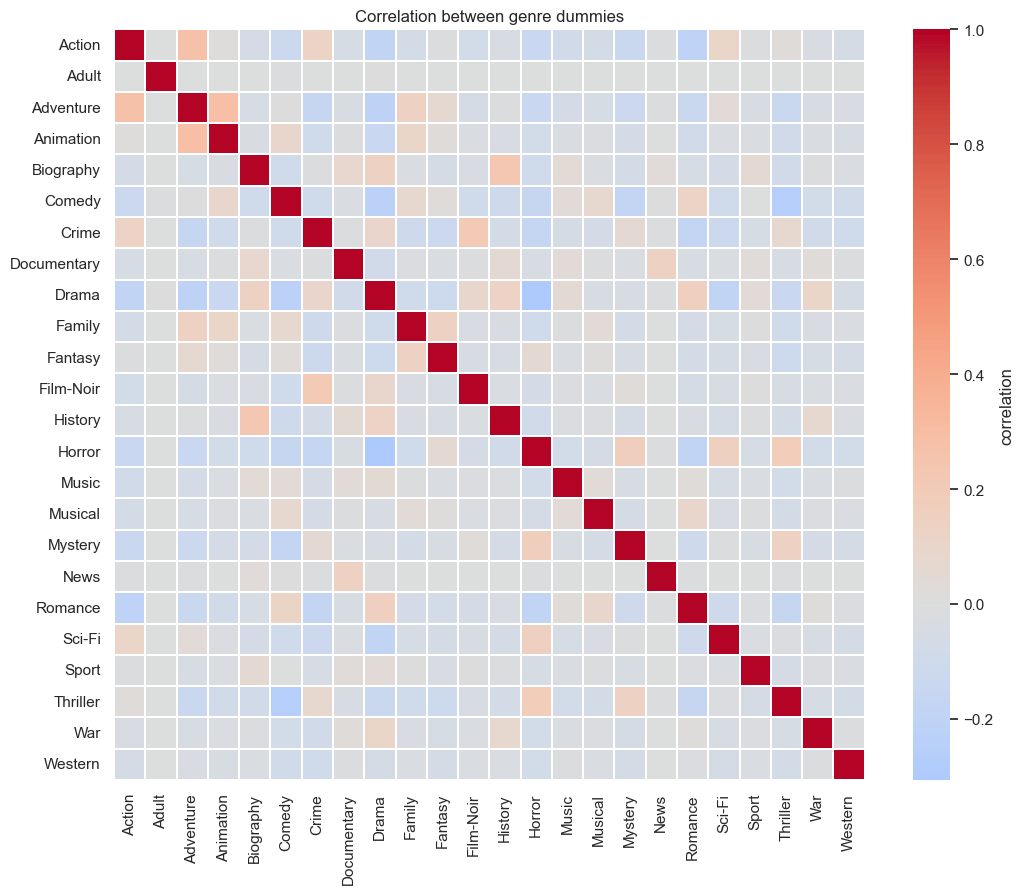

In [9]:
corr = df_f[genre_cols].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            linewidths=0.3, cbar_kws={"label": "correlation"})
plt.title("Correlation between genre dummies")
plt.tight_layout()
plt.show()

# TOKENS/CHARACTERS

        syn_chars  syn_tokens_approx
mean       5375.4             1220.7
median     3914.0              878.0
min         560.0              131.0
max       63959.0            14828.0


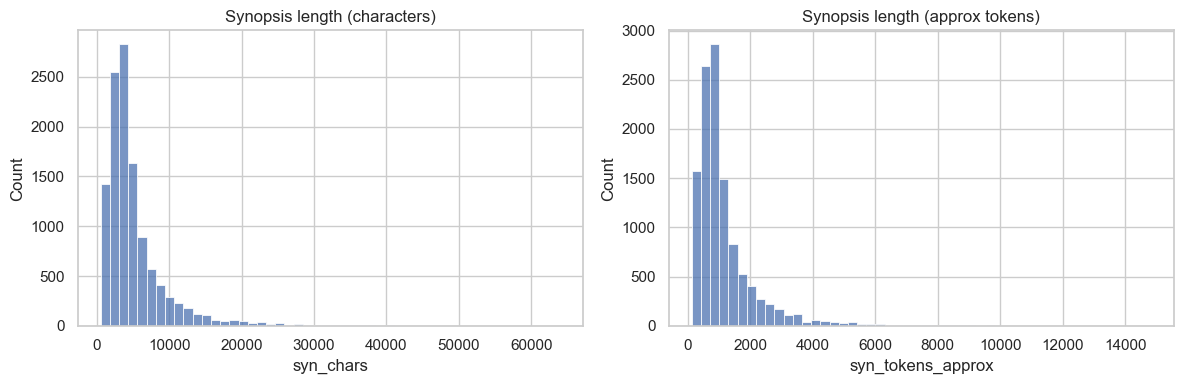

In [10]:
df_f["syn_chars"] = df_f["plot_synopsis"].fillna("").str.len()
df_f["syn_words"] = df_f["plot_synopsis"].fillna("").str.split().str.len()
df_f["syn_tokens_approx"] = (df_f["syn_words"] * 1.3).round()   # rule of thumb: ~1.3 tokens/word
 
length_stats = df_f[["syn_chars", "syn_tokens_approx"]].agg(["mean", "median", "min", "max"]).round(1)
print(length_stats)
 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_f["syn_chars"], bins=50, ax=axes[0])
axes[0].set_title("Synopsis length (characters)")
sns.histplot(df_f["syn_tokens_approx"], bins=50, ax=axes[1])
axes[1].set_title("Synopsis length (approx tokens)")
plt.tight_layout()
plt.show()


# VOCAB

In [11]:
tfidf = TfidfVectorizer(stop_words="english", max_features=5000, min_df=5)
x_text = tfidf.fit_transform(df_f["plot_synopsis"].fillna(""))
terms = np.array(tfidf.get_feature_names_out())
 
overall_mean = np.asarray(x_text.mean(axis=0)).ravel()
 
top_overall = pd.Series(overall_mean, index=terms).sort_values(ascending=False).head(15)
print("Top 15 terms overall:")
print(top_overall.round(4))

Top 15 terms overall:
tells     0.0171
man       0.0164
father    0.0157
house     0.0145
police    0.0142
home      0.0132
mother    0.0130
film      0.0129
family    0.0129
time      0.0127
new       0.0126
car       0.0119
goes      0.0118
later     0.0118
finds     0.0117
dtype: float64


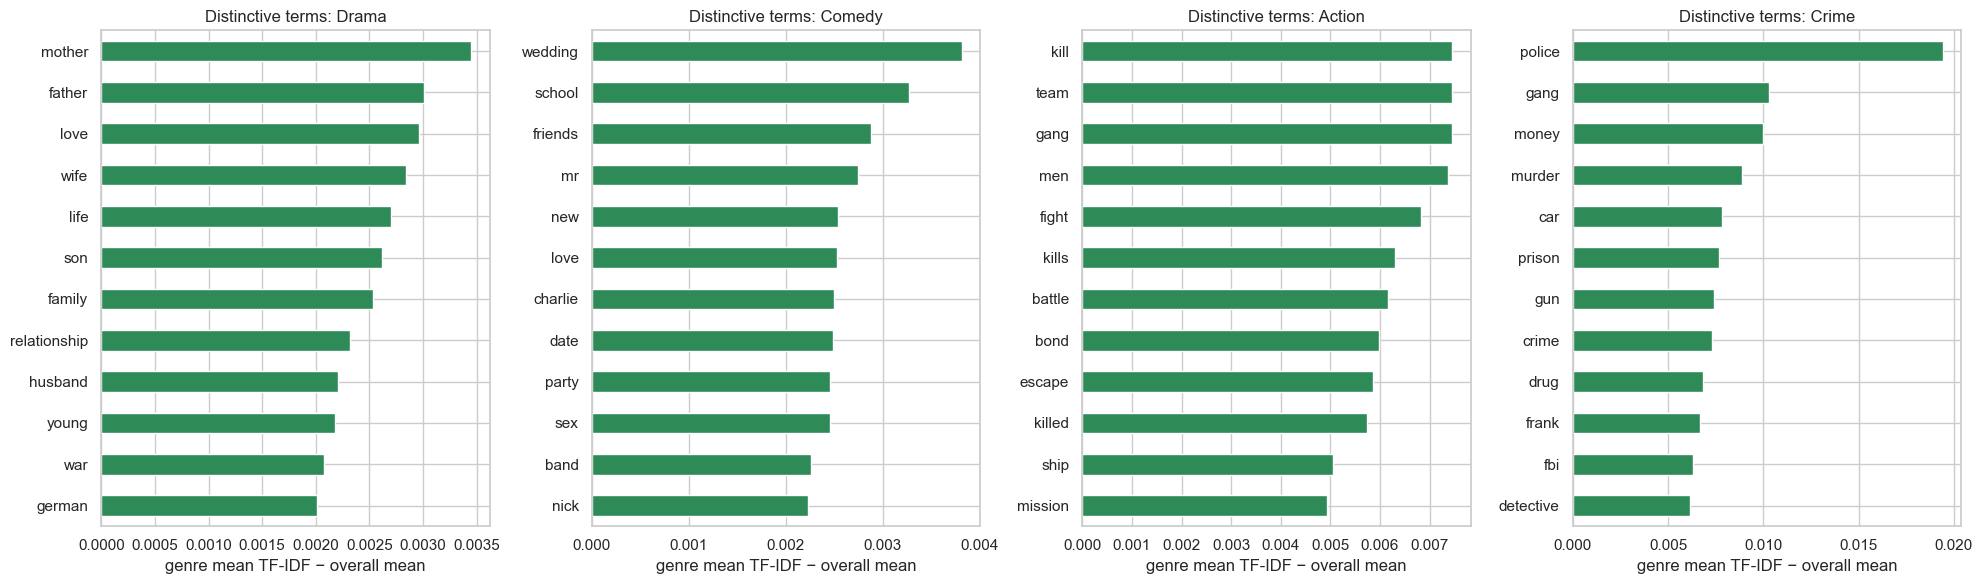

In [12]:
inspect_genres = balance.index[:4].tolist()
 
fig, axes = plt.subplots(1, len(inspect_genres), figsize=(5 * len(inspect_genres), 6))
axes = np.atleast_1d(axes)
 
for ax, g in zip(axes, inspect_genres):
    mask = (df_f[g] == 1).values
    genre_mean = np.asarray(x_text[mask].mean(axis=0)).ravel()
    lift = pd.Series(genre_mean - overall_mean, index=terms).sort_values(ascending=False).head(12)
    lift.iloc[::-1].plot.barh(ax=ax, color="seagreen")
    ax.set_title(f"Distinctive terms: {g}")
    ax.set_xlabel("genre mean TF-IDF − overall mean")
 
plt.tight_layout()
plt.show()

# TAKEAWAYS 

I would have guessed love and relationships would have placed higher in this category.  War and German really threw me off. Comedy is interesting because technically you can make a comedy out of anything.  Action has three versions of the word kill so that seems to align. Crime makes perfect sense with Police have a rating twice as much as every other category.  